# Janelas temporais (small) - Tiago Gonçalves
Validação das janelas, Gantt, viabilidade com as regras do `rules.csv` e matriz de compatibilidade.
Requer `loader.py` e `windows.py` na mesma pasta deste notebook.

## 1. Carregamento e validação das janelas

In [2]:
from loader import load_dataset, summary
from windows import *

ds = load_dataset("docs/small")   # ajustar o caminho para a pasta com os CSVs
summary(ds)

Dataset: docs\small
  collection_centers       1 linhas x  5 colunas
  customers               21 linhas x  5 colunas
  delivery_locations       7 linhas x  5 colunas
  distance_matrix        182 linhas x  6 colunas
  localities              49 linhas x  6 colunas
  locations               14 linhas x  7 colunas
  order_items             80 linhas x  9 colunas
  orders                  25 linhas x  5 colunas
  producers                6 linhas x  6 colunas
  products                31 linhas x  6 colunas
  vehicles                 2 linhas x  6 colunas
Regras: {'start_date': '2026-10-30', 'horizon_days': 2, 'flow': 'producer>warehouse>delivery_location', 'stop_service_min': 10, 'warehouse_handling_min': 15, 'max_warehouse_dwell_h': 24, 'window_semantics': 'service_start', 'avg_speed_kmh': 45.0, 'route_factor': 1.3, 'generator_seed': 1}

Verificacoes:
  itens sem produtor/local de entrega: 0
  valores em falta em order_items: 0
  pares em falta na distance_matrix: 0


In [3]:
# Todas as linhas devem ter ok=True
display(validate_windows(ds))
display(window_stats(ds))

,violacoes,ok
valores em falta nas colunas de tempo,0,True
availability_start >= availability_end,0,True
delivery_start >= delivery_end,0,True
delivery_end <= availability_start (entrega fecha antes da recolha abrir),0,True
delivery_start < availability_start (entrega abre antes da recolha),0,True
janelas do mesmo pedido com delivery diferente,0,True
recolha fora do horizonte (+1 dia para entregas),0,True
entrega fora do horizonte (+1 dia),0,True
[info] encomenda feita depois de availability_start,0,True


,largura recolha (min),largura entrega (min),espaco recolha->entrega (min)
count,80.0,80.0,80.0
mean,160.7,149.8,705.0
std,39.5,36.7,516.5
min,90.0,90.0,225.0
25%,135.0,120.0,371.2
50%,150.0,150.0,472.5
75%,180.0,195.0,817.5
max,240.0,225.0,1665.0


## 2. Gantt das janelas (por dia)

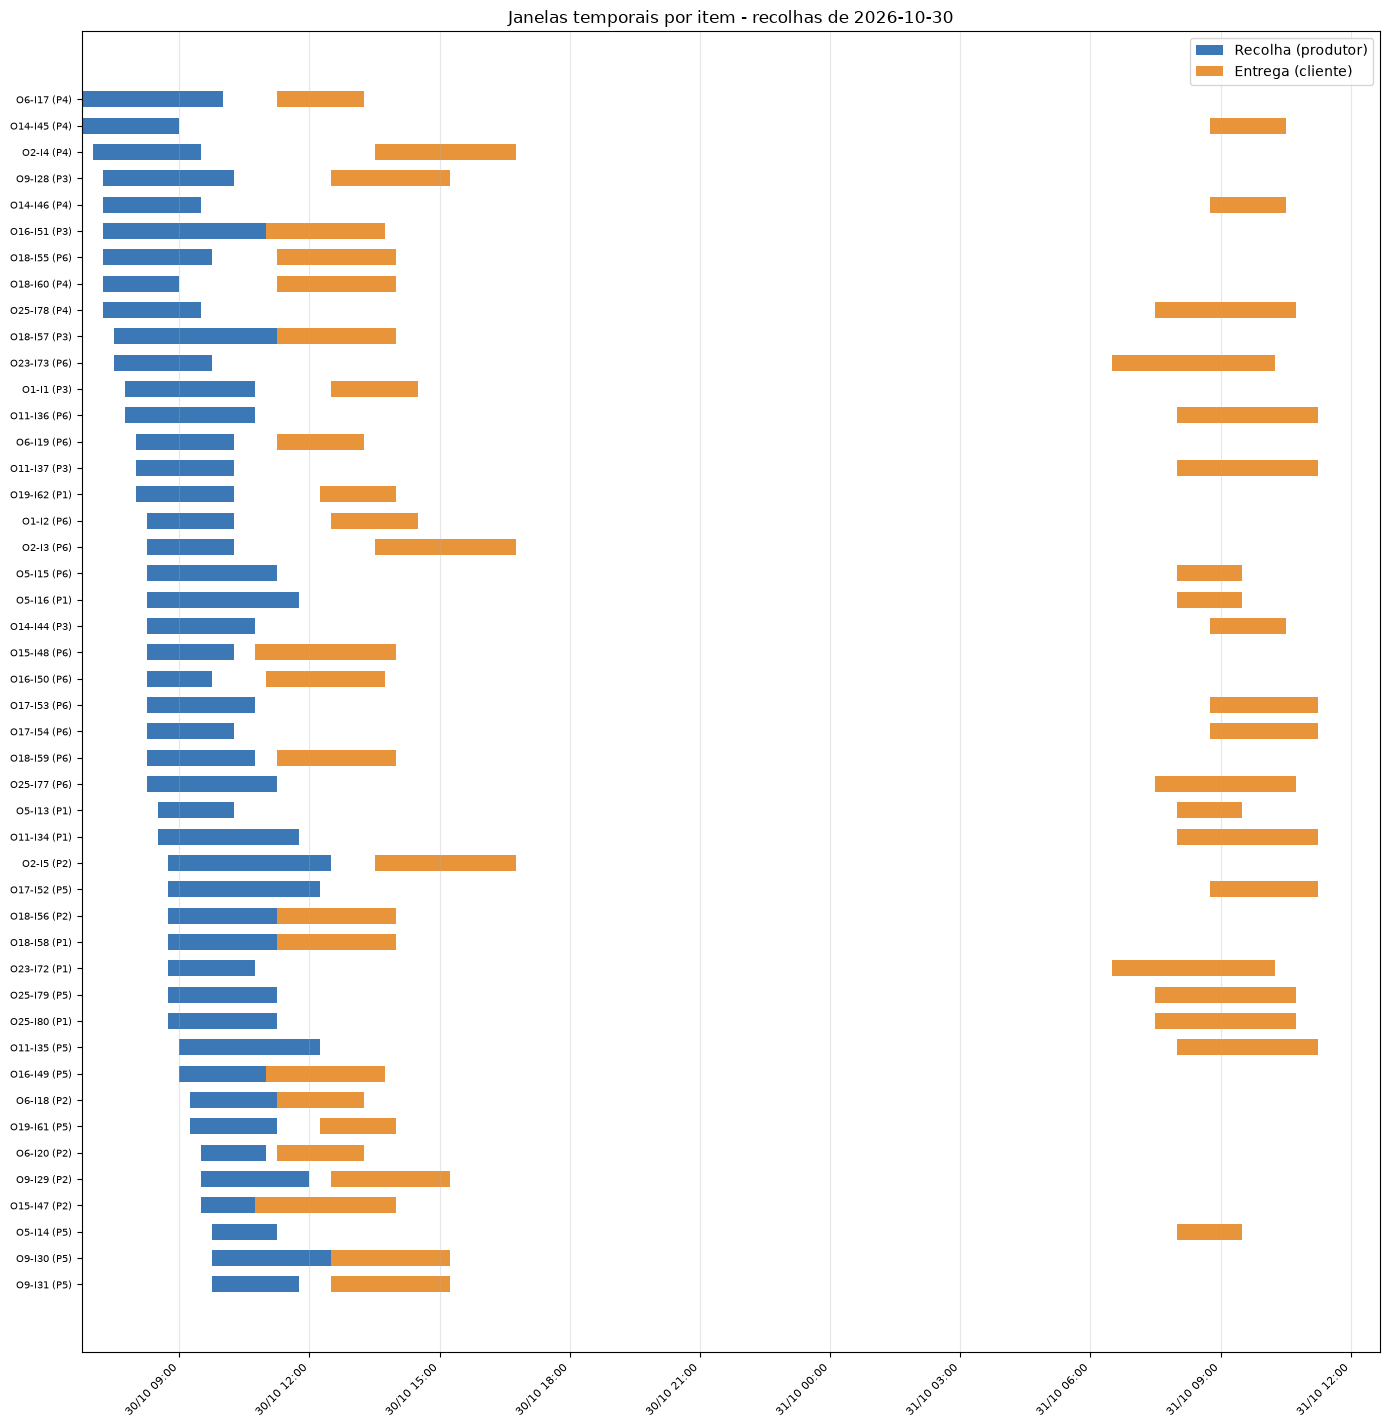

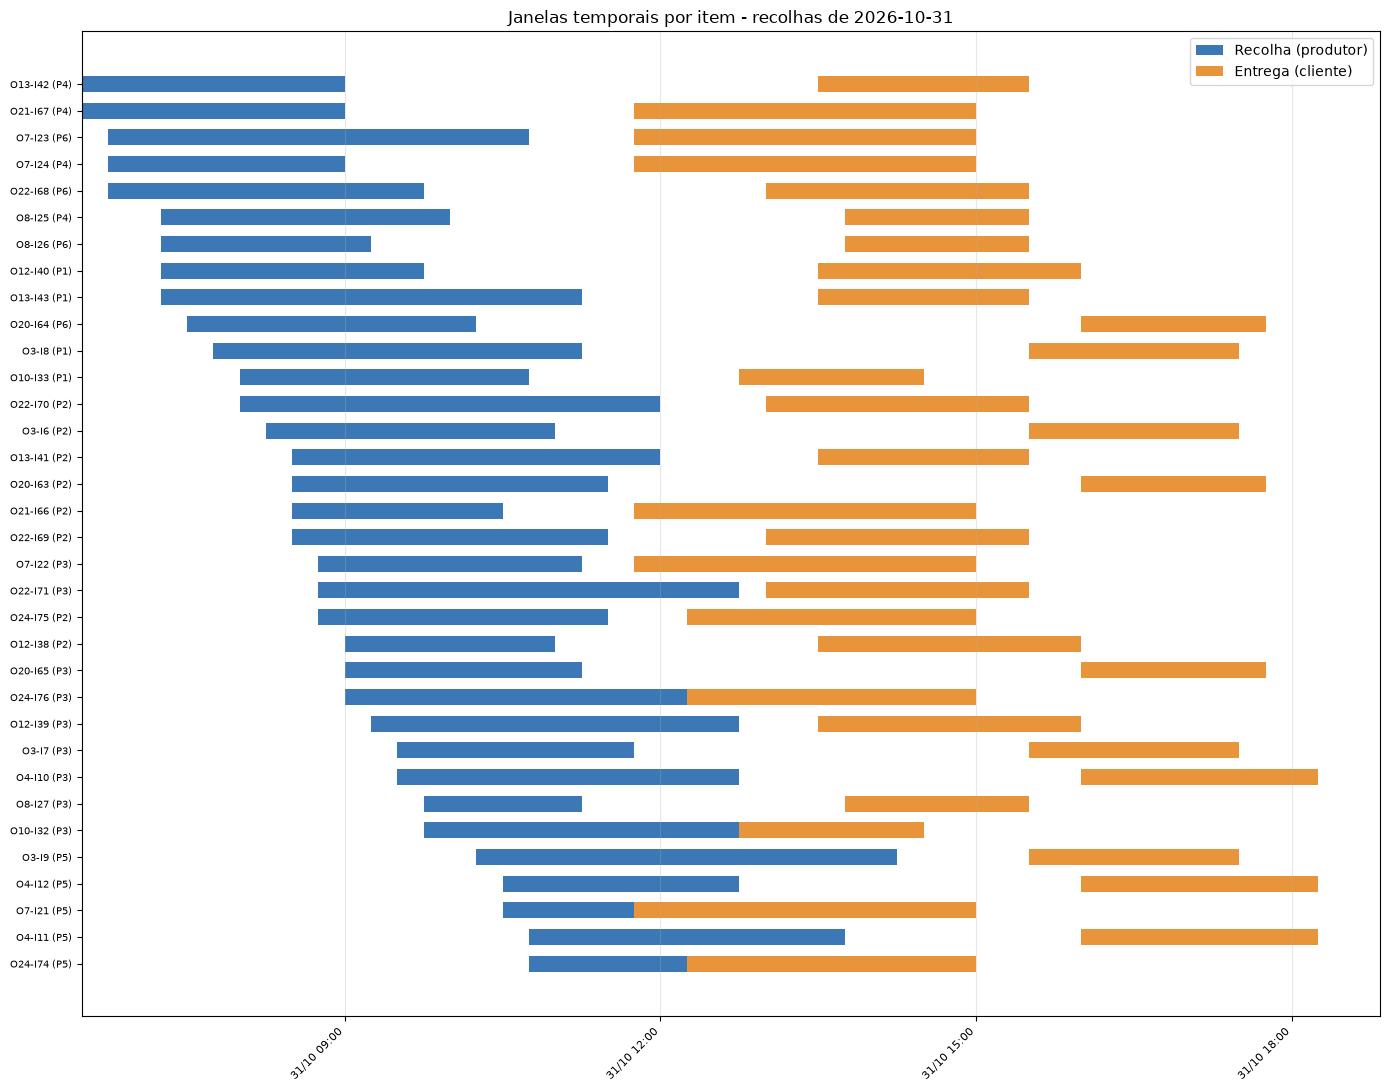

In [4]:
for day in ["2026-10-30", "2026-10-31"]:
    plot_gantt(ds, day=day)
    plt.show()

## 3. Viabilidade com e sem regras
Cadeia com regras: 10 min de serviço no produtor + viagem ao armazém + manuseamento (15 + 15 min) + viagem ao cliente.
Com `window_semantics = service_start`, o serviço no cliente não conta para o prazo.
Folga = `delivery_end` - chegada mais cedo. Limiar de "apertado": 240 min (justificar).

,sem regras,com regras
confortavel,71.0,63.0
apertado,9.0,17.0
impossivel,0.0,0.0
espera media ate delivery_start (min),512.5,450.1
folga media (min),662.3,598.7
folga minima (min),189.7,110.6


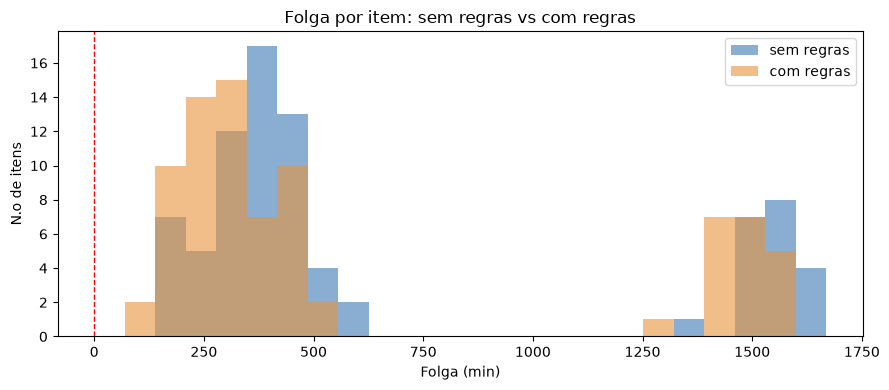

In [5]:
feas = feasibility(ds, handling_ops=2, tight_min=240)
display(feasibility_summary(feas))
plot_slack(feas); plt.show()

In [7]:
# Itens mais apertados com regras
display(feas.sort_values("folga_com")[
    ["order_item_id", "producer_id", "cadeia_com", "folga_sem", "folga_com", "classe_com"]].head(10))

,order_item_id,producer_id,cadeia_com,folga_sem,folga_com,classe_com
19,20,2,114.4,192.8,110.6,apertado
17,18,2,114.4,207.8,125.6,apertado
73,74,5,110.9,189.7,144.1,apertado
20,21,5,110.9,204.7,159.1,apertado
46,47,2,109.3,235.0,160.7,apertado
60,61,5,121.5,204.5,163.5,apertado
29,30,5,161.6,208.5,168.4,apertado
30,31,5,161.6,208.5,168.4,apertado
48,49,5,110.9,219.7,174.1,apertado
28,29,2,160.0,311.0,185.0,apertado


## 4. Matriz de compatibilidade entre itens (extra)

Pares compatíveis: 1621 de 6320


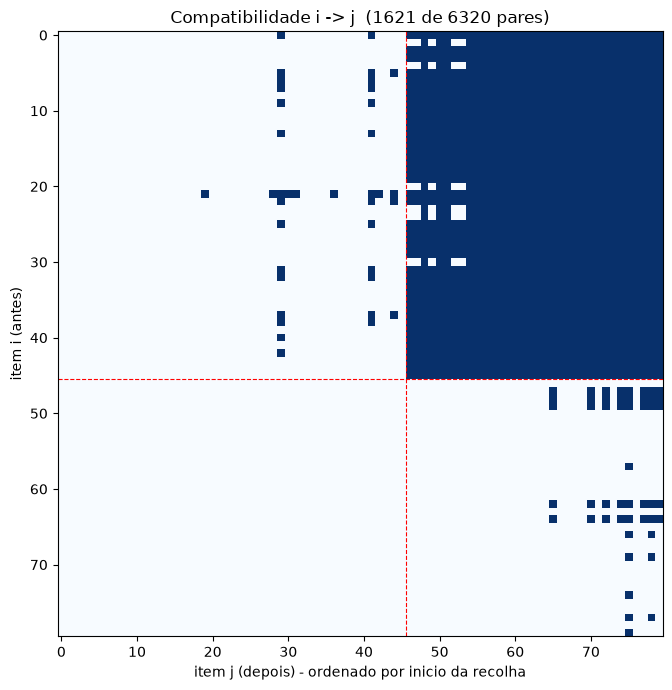

In [9]:
C = compat_matrix(ds, feas)
print("Pares compatíveis:", int(C.values.sum()), "de", len(C) * (len(C) - 1))
plot_compat(C, ds); plt.show()

**Interpretação.** A linha tracejada separa os itens cuja recolha abre a 30/10 (46 itens)
dos de 31/10 (34 itens). Dos 1 621 pares compatíveis, 1 534 vão do dia 30 para o dia 31.
Nenhum item do dia 31 pode ser servido antes de um do dia 30. Dentro do mesmo dia, quase
nenhum par é compatível (38 no dia 30 e 49 no dia 31), porque as janelas de recolha são
curtas e a cadeia completa de um item (cerca de 100 min mais viagens) ocupa quase toda a manhã.

**Conclusão.** Servir os itens um a um, com a cadeia completa, não chega para o mesmo dia.
Com 2 veículos e 46 itens no dia 30, é preciso agrupar vários itens por viagem
(recolher vários antes de ir ao armazém). Isto justifica modelar rotas com várias
paragens e não item a item, e é a ponte para as restrições do CSP e para a capacidade.

## 5. Restrições para o CSP
(a preencher: domínio da recolha por item = `[availability_start, dom_fim_recolha_com]`, janelas, precedência produtor → armazém → cliente, permanência máxima de 24 h no armazém, tempos de viagem.)